**Lab assignment 1**

Advanced notebook aimed at making detailed comparisons between heuristics.

It includes graphical visualization and quantitative analysis to support the justification of
results.

**Authors:** Borys Szycher, Marcin Otte

In [1]:
# %pip install matplotlib tabulate numpy 

> **IMPORTANT**: you may need to install several python packages depending on the computer you are working with. Lab computers should have all necessary packages installed.
> To install the packages, uncomment (removing the #) and run the line above.

# Activity 7 – Analysing the two best heuristics
Statistical comparison of two of **our own** heuristics over n random puzzles:
* **A\* Euclid + LC** (Activity 4): Euclidean distance + linear conflicts, used with A\*.
* **Proposed (1.5x)** (Activity 5, our new proposal): `1.5 · (max(Euclid, RowCol) + LC)`, a weighted A\*.

Metrics to compare:
- Cost of the solution (number of movements) – solution quality
- Number of generated / expanded nodes and maximum number of nodes stored – memory
- Execution time
- Difference between solutions

## Why these two heuristics?

Only the heuristics we implemented ourselves are candidates: Misplaced, Euclid, RowCol and Euclid + LC (Activities 1–4), plus our two proposals of Activity 5. The heuristics given with the template (Manhattan, MD + LC) are not considered. The choice is based on the experiments of notebook `puzzle-p2` (`euclidian` returns the Euclidean distance rounded down, `int(total)`; the same definition is used here).

Mean expanded nodes in the 30-instance 3×3 benchmark of `puzzle-p2`, and expanded nodes on the 4×4 and 5×5 examples:

| Heuristic | 3×3 mean expanded | optimal | 4×4 example | 5×5 example |
|---|---|---|---|---|
| Misplaced | 9435 | 30/30 | > 90 s, not finished | not run |
| RowCol | 2355 | 30/30 | > 90 s, not finished | 614,794 |
| A\* Euclid | 1564 | 30/30 | 2,335,084 | 258,654 |
| **A\* Euclid + LC** | **915.5** | 30/30 | **454,045** | **146,472** |
| Proposed (A\*) | 848 | 30/30 | 422,052 | 141,523 |
| **Proposed (1.5x)** | **364.8** | 28/30 | **9,202** | **36,022** |

* **A\* Euclid + LC** is the best heuristic of Activities 1–4. It is admissible, so A\* with it always finds the optimal solution, and it expands far fewer nodes than Misplaced, RowCol and Euclid on every board size.
* **Proposed (1.5x)** is the best of all our heuristics: it expands the fewest nodes of all (2.5× fewer than Euclid + LC on 3×3, 49× fewer on the 4×4 example). The price is that it is not admissible, so its solutions are only guaranteed to be ≤ 1.5 × optimal.
* Proposed (A\*) was not chosen because it is almost the same heuristic as Euclid + LC (max(Euclid, RowCol) + LC differs only when RowCol > Euclid) and gives nearly identical results. Comparing one heuristic from Activities 1–4 with our new proposal is more informative.

The two heuristics represent the two sides of the trade-off: an optimal A\* against a weighted A that gives up the optimality guarantee to save search effort. Because Euclid + LC is admissible, its cost is the optimal cost, so it also measures how many extra moves the weighted proposal costs.

In [2]:
# Import the required libraries
import math
import io
import contextlib
import random
import time
import statistics
import matplotlib.pyplot as plt
import search
from search import *

The heuristics are defined in `puzzle-p2`; each notebook has its own kernel, so they are defined and registered again here (same code).

In [3]:
def euclidian(state, end_state):
    size = int(math.sqrt(len(state)))
    total = 0.0
    for tile in range(1, len(state)):
        idx = state.index(tile)
        goal = end_state.index(tile)
        total += math.sqrt((idx // size - goal // size) ** 2 + (idx % size - goal % size) ** 2)
    return int(total)   # same as in puzzle-p2: Euclidean distance rounded down

def rows_columns(state, end_state):
    size = int(math.sqrt(len(state)))
    total = 0
    for tile in range(1, len(state)):
        idx = state.index(tile)
        goal = end_state.index(tile)
        total += (idx // size != goal // size) + (idx % size != goal % size)
    return total

def combination(state, end_state):
    return max(euclidian(state, end_state), rows_columns(state, end_state)) + getLinear_conflict(state, end_state)

W = 1.5

def combination_2(state, end_state):
    return W * combination(state, end_state)

def euclidian_plus_lc(state, end_state):
    return euclidian(state, end_state) + getLinear_conflict(state, end_state)

register_heuristic("A* Euclid + LC", euclidian_plus_lc)
register_heuristic("Proposed (1.5x)", combination_2)

## Setting up and running the experiment

In [4]:
# Configuration
size = 3                 # Puzzle size
num_iterations = 1000    # Number of random puzzles
end_state = generate_spiral_state(size)
random.seed(2026)        # reproducible experiment

ALG_A = 'A* Euclid + LC'
ALG_B = 'Proposed (1.5x)'
metrics = ['cost', 'nodes_generated', 'nodes_expanded', 'max_nodes', 'time']
data = {ALG_A: {m: [] for m in metrics}, ALG_B: {m: [] for m in metrics}}
cost_differences = []   # Proposed - Euclid+LC (extra movements; Euclid+LC is optimal)
cost_ratios = []        # Proposed / Euclid+LC
time_differences = []   # Euclid+LC - Proposed

print(f"Running experiment with {num_iterations} puzzles {size}x{size}")
print("Goal state:")
visualize_state(end_state)

for i in range(num_iterations):
    initial_state = generate_random_state(size, end_state)
    if not isSolvable(initial_state, end_state):
        print(f"\nPuzzle {i+1}: is unsolvable, skipping")
        continue
    with contextlib.redirect_stdout(io.StringIO()):     # silence the "executed" messages
        res_a = run_algorithm(ALG_A, initial_state, end_state, size)[ALG_A]
        res_b = run_algorithm(ALG_B, initial_state, end_state, size)[ALG_B]
    for m in metrics:
        data[ALG_A][m].append(res_a[m])
        data[ALG_B][m].append(res_b[m])
    cost_differences.append(res_b['cost'] - res_a['cost'])
    cost_ratios.append(res_b['cost'] / res_a['cost'] if res_a['cost'] else 1.0)
    time_differences.append(res_a['time'] - res_b['time'])
    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{num_iterations} puzzles")

print("\nExperiment finished!")

Running experiment with 1000 puzzles 3x3
Goal state:
 1  2  3
 8     4
 7  6  5


Processed 100/1000 puzzles


Processed 200/1000 puzzles


Processed 300/1000 puzzles


Processed 400/1000 puzzles


...

Processed 600/1000 puzzles


Processed 700/1000 puzzles


Processed 800/1000 puzzles


Processed 900/1000 puzzles


Processed 1000/1000 puzzles

Experiment finished!


## Analysing the results

In [5]:
from tabulate import tabulate

def summary(values):
    return [min(values), max(values), statistics.mean(values), statistics.median(values)]

rows = []
labels = {'cost': 'Cost', 'nodes_generated': 'Nodes generated', 'nodes_expanded': 'Nodes expanded',
          'max_nodes': 'Max nodes stored', 'time': 'Time (s)'}
for m in metrics:
    for alg in (ALG_A, ALG_B):
        rows.append([labels[m], alg] + summary(data[alg][m]))
print(tabulate(rows, headers=["Metric", "Algorithm", "Min", "Max", "Mean", "Median"], floatfmt=".4g", tablefmt="grid"))

n = len(cost_differences)
optimal = sum(1 for d in cost_differences if d == 0)
print(f"\nSolutions of {ALG_B} with optimal cost: {optimal}/{n} ({100 * optimal / n:.1f}%)")
print(f"Cost differences ({ALG_B} - {ALG_A}): min {min(cost_differences)}, max {max(cost_differences)}, "
      f"mean {statistics.mean(cost_differences):.3f}")
print(f"Cost ratio {ALG_B}/{ALG_A}: mean {statistics.mean(cost_ratios):.4f}, max {max(cost_ratios):.4f} "
      f"(theoretical bound: {W})")

for m in ['nodes_generated', 'nodes_expanded', 'max_nodes', 'time']:
    a, b = statistics.mean(data[ALG_A][m]), statistics.mean(data[ALG_B][m])
    change = 100 * (b - a) / a
    print(f"Mean {labels[m]}: {ALG_B} = {b:.4g} vs {ALG_A} = {a:.4g}  ({change:+.1f}%)")
wins = sum(1 for x, y in zip(data[ALG_A]['nodes_expanded'], data[ALG_B]['nodes_expanded']) if y < x)
print(f"{ALG_B} expands fewer nodes than {ALG_A} in {wins}/{n} puzzles")

+------------------+-----------------+------------+--------------+------------+------------+
| Metric           | Algorithm       |        Min |          Max |       Mean |     Median |
+==================+=================+============+==============+============+============+
| Cost             | A* Euclid + LC  |  4         |   29         |   21.45    |   22       |
+------------------+-----------------+------------+--------------+------------+------------+
| Cost             | Proposed (1.5x) |  4         |   30         |   21.52    |   22       |
+------------------+-----------------+------------+--------------+------------+------------+
| Nodes generated  | A* Euclid + LC  | 11         |    3.193e+04 | 2927       | 1555       |
+------------------+-----------------+------------+--------------+------------+------------+
| Nodes generated  | Proposed (1.5x) | 11         |    1.359e+04 | 1210       |  752.5     |
+------------------+-----------------+------------+--------------+----

## Visualizing the results

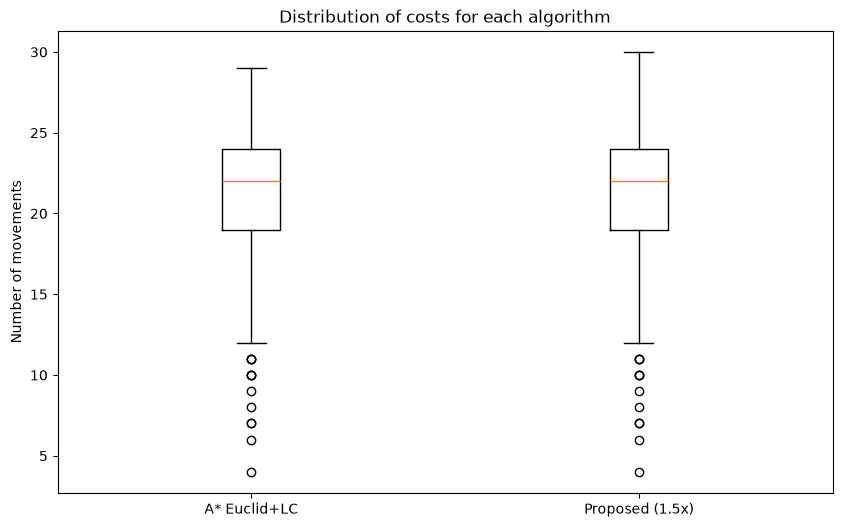

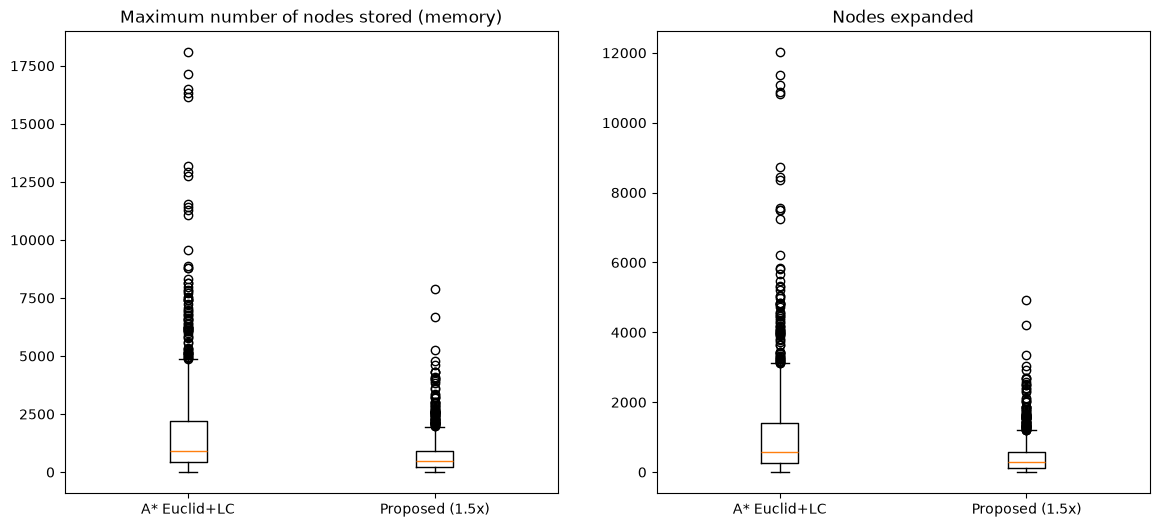

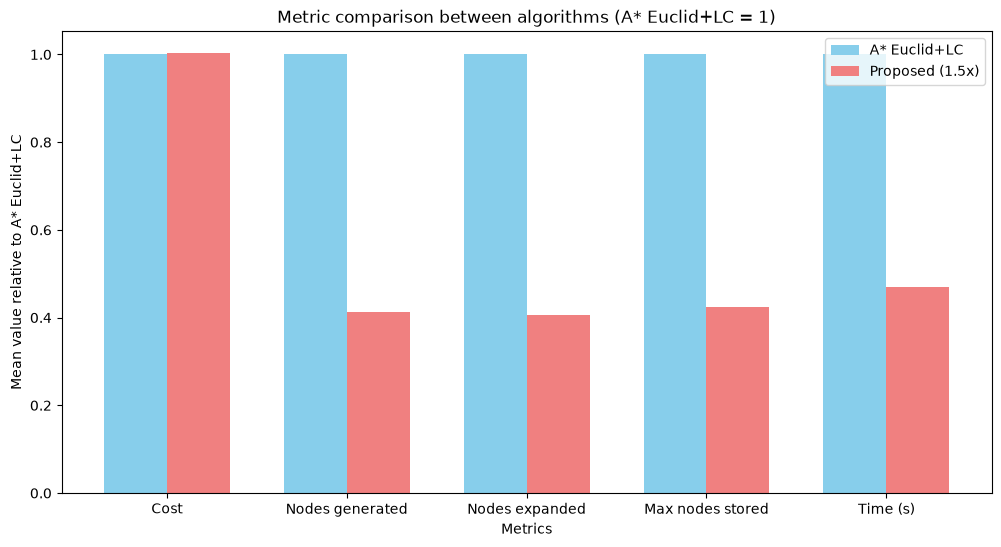

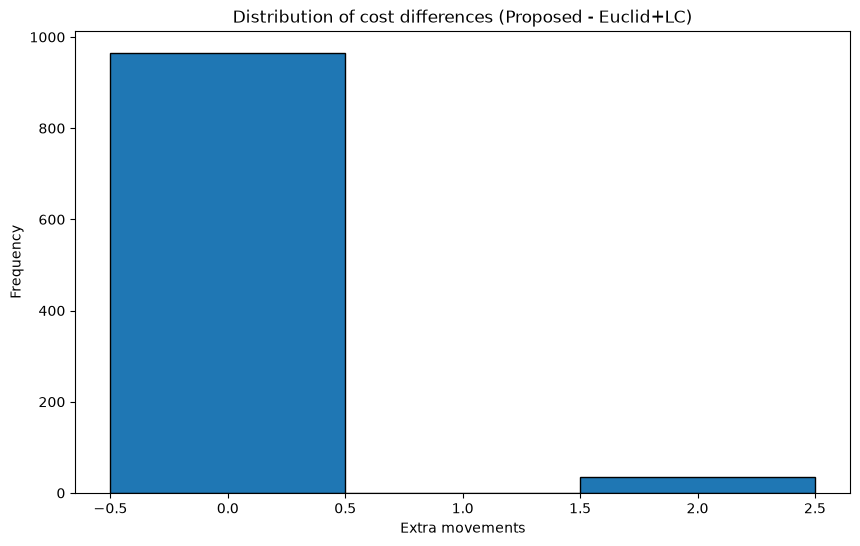

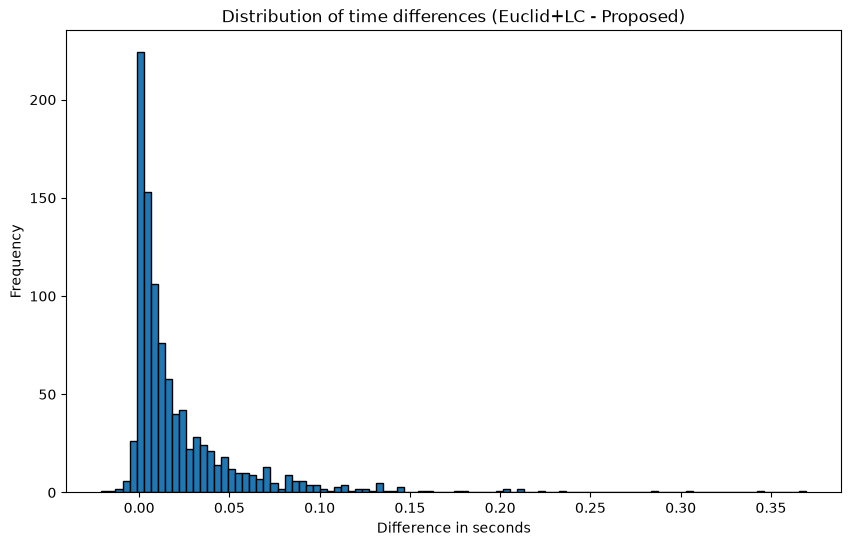

In [6]:
names = ['A* Euclid+LC', 'Proposed (1.5x)']

# Box plot for costs
plt.figure(figsize=(10, 6))
plt.boxplot([data[ALG_A]['cost'], data[ALG_B]['cost']])
plt.title('Distribution of costs for each algorithm')
plt.ylabel('Number of movements')
plt.xticks([1, 2], names)
plt.show()

# Box plots for memory (max nodes stored) and expanded nodes
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].boxplot([data[ALG_A]['max_nodes'], data[ALG_B]['max_nodes']])
axes[0].set_title('Maximum number of nodes stored (memory)')
axes[0].set_xticks([1, 2], names)
axes[1].boxplot([data[ALG_A]['nodes_expanded'], data[ALG_B]['nodes_expanded']])
axes[1].set_title('Nodes expanded')
axes[1].set_xticks([1, 2], names)
plt.show()

# Bar chart for mean stats (normalised to A* Euclid+LC = 1 so that all metrics fit in one plot)
bar_metrics = ['cost', 'nodes_generated', 'nodes_expanded', 'max_nodes', 'time']
a_vals = [1.0] * len(bar_metrics)
b_vals = [statistics.mean(data[ALG_B][m]) / statistics.mean(data[ALG_A][m]) for m in bar_metrics]
x = range(len(bar_metrics))
width = 0.35
plt.figure(figsize=(12, 6))
plt.bar([i - width/2 for i in x], a_vals, width, label='A* Euclid+LC', color='skyblue')
plt.bar([i + width/2 for i in x], b_vals, width, label='Proposed (1.5x)', color='lightcoral')
plt.xlabel('Metrics')
plt.ylabel('Mean value relative to A* Euclid+LC')
plt.title('Metric comparison between algorithms (A* Euclid+LC = 1)')
plt.xticks(x, [labels[m] for m in bar_metrics])
plt.legend()
plt.show()

# Histogram of cost differences
plt.figure(figsize=(10, 6))
plt.hist(cost_differences, bins=range(min(cost_differences), max(cost_differences) + 2), edgecolor='black', align='left')
plt.title('Distribution of cost differences (Proposed - Euclid+LC)')
plt.xlabel('Extra movements')
plt.ylabel('Frequency')
plt.show()

# Histogram of time differences
plt.figure(figsize=(10, 6))
plt.hist(time_differences, bins=100, edgecolor='black')
plt.title('Distribution of time differences (Euclid+LC - Proposed)')
plt.xlabel('Difference in seconds')
plt.ylabel('Frequency')
plt.show()

## Scaling to a harder problem: 4×4 puzzle

On the 3×3 puzzle both searches are cheap. To see how they scale, the same comparison is repeated on 4×4 instances. Fully random 4×4 states (optimal solutions of ~50 moves) are out of reach for A\* Euclid + LC in Python: on the bulletin's 4×4 state (cost 41) it already needs 454,045 expanded nodes and ~34 s. With 50 random moves, one test instance (cost 44) took 460 s. So each instance is produced by applying **30 random moves** (without immediately undoing the previous one) to the goal state. This gives optimal costs of up to ~30 moves, and **50 puzzles** are solved.

+------------------+-----------------+------------+------------+--------------+------------+
| Metric           | Algorithm       |        Min |        Max |         Mean |     Median |
+==================+=================+============+============+==============+============+
| Cost             | A* Euclid + LC  |  16        | 30         |   26.08      |   28       |
+------------------+-----------------+------------+------------+--------------+------------+
| Cost             | Proposed (1.5x) |  16        | 32         |   26.64      |   28       |
+------------------+-----------------+------------+------------+--------------+------------+
| Nodes generated  | A* Euclid + LC  | 101        |  1.278e+05 |    1.719e+04 | 7192       |
+------------------+-----------------+------------+------------+--------------+------------+
| Nodes generated  | Proposed (1.5x) |  52        |  3.738e+04 | 4372         | 1712       |
+------------------+-----------------+------------+------------+------

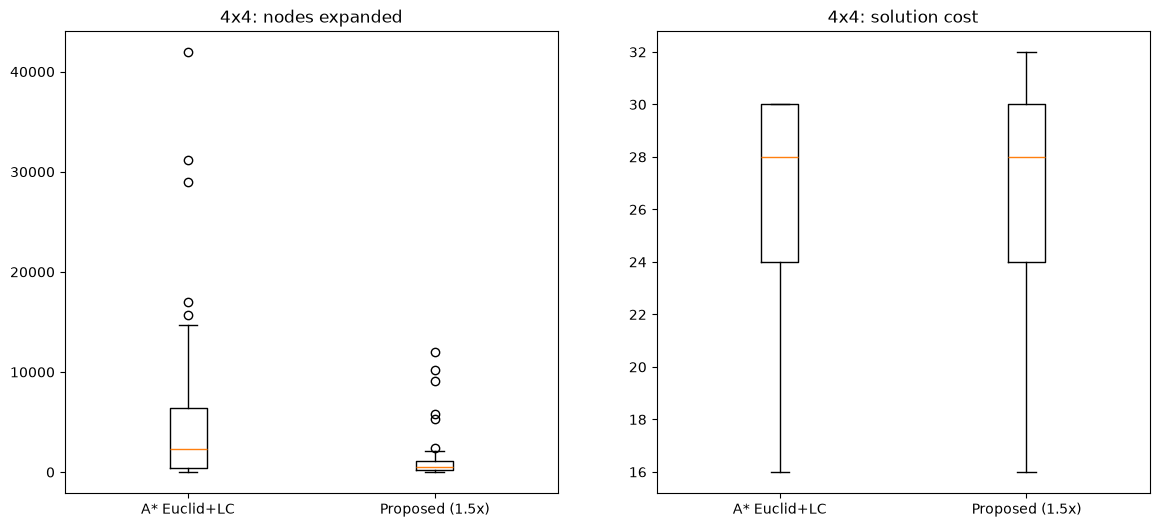

In [7]:
def scramble(end_state, size, moves):
    """Random walk of `moves` steps from the goal (never undoing the previous move)."""
    state, previous = end_state[:], None
    for _ in range(moves):
        options = [c for c in getChildren(state, size) if c != previous]
        previous, state = state, random.choice(options)
    return state

size4 = 4
end_state4 = generate_ordered_state(size4)
num_puzzles4 = 50
random.seed(4)

data4 = {ALG_A: {m: [] for m in metrics}, ALG_B: {m: [] for m in metrics}}
for i in range(num_puzzles4):
    s = scramble(end_state4, size4, 30)
    with contextlib.redirect_stdout(io.StringIO()):
        res_a = run_algorithm(ALG_A, s, end_state4, size4)[ALG_A]
        res_b = run_algorithm(ALG_B, s, end_state4, size4)[ALG_B]
    for m in metrics:
        data4[ALG_A][m].append(res_a[m])
        data4[ALG_B][m].append(res_b[m])

rows = []
for m in metrics:
    for alg in (ALG_A, ALG_B):
        rows.append([labels[m], alg] + summary(data4[alg][m]))
print(tabulate(rows, headers=["Metric", "Algorithm", "Min", "Max", "Mean", "Median"], floatfmt=".4g", tablefmt="grid"))

diff4 = [b - a for a, b in zip(data4[ALG_A]['cost'], data4[ALG_B]['cost'])]
print(f"\n{ALG_B} optimal in {sum(1 for d in diff4 if d == 0)}/{num_puzzles4} puzzles; "
      f"extra cost: max {max(diff4)}, mean {statistics.mean(diff4):.2f}")
for m in ['nodes_generated', 'nodes_expanded', 'max_nodes', 'time']:
    a, b = statistics.mean(data4[ALG_A][m]), statistics.mean(data4[ALG_B][m])
    print(f"Mean {labels[m]}: {ALG_B} = {b:.4g} vs {ALG_A} = {a:.4g}  ({100 * (b - a) / a:+.1f}%)")
wins4 = sum(1 for x, y in zip(data4[ALG_A]['nodes_expanded'], data4[ALG_B]['nodes_expanded']) if y < x)
print(f"{ALG_B} expands fewer nodes than {ALG_A} in {wins4}/{num_puzzles4} puzzles")

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.boxplot([data4[ALG_A]['nodes_expanded'], data4[ALG_B]['nodes_expanded']])
plt.xticks([1, 2], names)
plt.title('4x4: nodes expanded')
plt.subplot(1, 2, 2)
plt.boxplot([data4[ALG_A]['cost'], data4[ALG_B]['cost']])
plt.xticks([1, 2], names)
plt.title('4x4: solution cost')
plt.show()

## Conclusions

**Solution quality (cost)**
* A\* Euclid + LC is admissible, so it always finds the optimal solution (3×3 mean cost 21.45; 4×4 mean cost 26.08).
* Proposed (1.5x) found the optimal solution in **965/1000** 3×3 puzzles (96.5%). Its solutions are at most **2 moves** longer (mean +0.07 moves). The worst cost ratio is **1.105**, far below the theoretical bound of 1.5.
* On 4×4 the loss grows a little: optimal in **36/50** puzzles, at most **+2** moves, mean +0.56 (mean cost 26.64 vs 26.08, about +2%).

**Computational cost (time and memory)**
* 3×3 (1000 puzzles): Proposed (1.5x) generates **−58.7%** nodes and expands **−59.4%** (447.8 vs 1102). It stores **−57.7%** nodes in memory (max nodes stored: mean 728.3 vs 1720) and needs **−52.9%** time (0.0207 s vs 0.0440 s). It expands fewer nodes in **964/1000** puzzles.
* 4×4 (50 puzzles): **−75.1%** expanded nodes (1405 vs 5651), **−74.0%** memory (2860 vs 11,020 stored nodes) and **−69.9%** time (0.12 s vs 0.40 s). It expands fewer nodes in 47/50 puzzles.
* The saving in time is slightly smaller than the saving in nodes because Proposed (1.5x) costs a bit more per node: it computes RowCol in addition to Euclid and LC.
* The advantage grows with the difficulty of the problem: from about 2.5× fewer nodes on 3×3 to 4× on the 4×4 scrambles. On the bulletin's 4×4 state of `puzzle-p2` it was 49× (9,202 vs 454,045 nodes), with the same optimal cost 41.

**Interpretation**
Euclid + LC is a weak admissible estimate: for a tile displaced diagonally the Euclidean distance is only ≈0.71 × the moves it needs. A\* therefore has to explore many states whose f-value is below the optimal cost. Multiplying the estimate by 1.5 pushes it close to the real distance (and sometimes above it). The search is guided much more directly towards the goal, at the price of losing the admissibility guarantee. In practice the overestimation is small, so solutions are almost always optimal, and when they are not, they are only 1–2 moves longer.

**Final verdict**: if the optimal solution is mandatory, **A\* Euclid + LC** must be used (admissible, always optimal). If a solution that is "almost always optimal, never much worse" is acceptable, **Proposed (1.5x)** is clearly the better choice. It needs about 2–4× fewer nodes, less memory and less time, and the benefit grows with the size of the puzzle, which is where search effort really matters.
